# 08 — Hogares y viviendas: el mismo modelo con otras unidades

La base de manzanas trae, además de las 82 columnas de personas, conteos de **hogares** y de **viviendas** (tenencia, combustible, servicios, tipo de vivienda, materialidad, agua, saneamiento, etc.). Aquí se aplica el mismo método de los notebooks 03–05 a cada una de esas unidades por separado. El resultado son dos modelos más, cada uno con su $W$ por comuna y su base de cruces bivariados por manzana:

| | Personas (05) | **Viviendas** | **Hogares** |
|---|---|---|---|
| Unidad | personas | viviendas particulares (ocupadas y desocupadas) | hogares en viviendas particulares |
| Total por manzana (hace de `n_per`) | `n_per` | `n_vp` | `n_hog` |
| Bloques con marginal por manzana | 27 | 13 | 15 |
| Columnas usadas | 82 | 63 | 35 |
| $W$ por comuna | `resultados/pais/modelos/` | `resultados/pais/viviendas/modelos/` | `resultados/pais/hogares/modelos/` |
| Cruces por manzana | `resultados/pais/cruces/` | `resultados/pais/viviendas/cruces/` | `resultados/pais/hogares/cruces/` |

Para cada unidad $u$ se estima $W_u[\text{perfil},\text{manzana}]$, el número esperado de unidades de cada perfil en cada manzana. Es la solución de mínima divergencia KL a la semilla uniforme que cumple la conjunta comunal de la unidad (filas) y sus marginales publicados por manzana (columnas). El algoritmo, el código del ajuste (`ipf_perfiles_gpu_rapido`) y el criterio de convergencia son los mismos de personas: cada celda restringida debe cumplir $|\text{error}|\le\max(0{,}1;\ 10^{-4}\cdot\text{total de la manzana})$.

Los tres modelos son independientes. Los cruces entre unidades (persona × hogar, hogar × vivienda) quedan para un paso posterior.

**Orden:** H0 universos y mapeo · H1 inventario en Independencia · H2 ajuste en Independencia · H3 validación con verdad conocida (provincias) · H4 diagnóstico del país · H5 corrida nacional · H6 validación con totales publicados que el modelo no usa · H7 la base de cruces y mapas.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from manzanas.datos import cargar_mapa, ruta_comuna
from manzanas.diccionario import codigos_microdato, glosas_manzana
from manzanas.inventario import etiquetas_bloque
from manzanas.pais import RUTA_COMUNAS, RUTA_PAIS, diagnosticar_unidad, procesar_comuna, rutas_unidad
from manzanas.perfiles import cargar_modelo, codigos_bloque, errores_modelo
from manzanas.provincias import (METODOS, NIVEL_2_UNIDADES, RUTA_VALIDACION, ajustar_provincia, comunas_por_provincia,
                                 datos_provincia_unidad, evaluar_cruces, evaluar_nivel_2)
from manzanas.unidades import (COLUMNAS_SIN_USAR, MAPEOS, TOTAL, TOTALES_VALIDACION, cargar_unidad, predecir_total,
                               tabla_viviendas)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
TOL, TOL_REL, N_ITER = 0.1, 1e-4, 20000  # mismo criterio que personas (05_pais.ipynb y scripts/correr_pais.py)
COMUNA_CUT = 13108                       # Independencia
UNIDADES = ["viviendas", "hogares"]
CUTS = sorted(int(f[len("personas_"):-len(".parquet")]) for f in os.listdir(RUTA_COMUNAS) if f.startswith("personas_"))

# Paleta de 06: secuencial de un tono (azul) y divergente azul <-> rojo con gris neutro al centro
AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
SECUENCIAL = LinearSegmentedColormap.from_list("azul", AZUL)
DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f3a9a3", "#e34948", "#9b1c1c"])
TEXTO, TEXTO_2, GRILLA = "#0b0b0b", "#52514e", "#e2e1dc"
plt.rcParams.update({"axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
                     "text.color": TEXTO, "axes.titlesize": 12, "font.size": 10})
NOMBRES_METODO = {"modelo": "Modelo (todos los bloques)", "raking_2": "Raking de 2 bloques", "independencia": "Independencia",
                  "provincial": "Estructura provincial", "condicional_1": "Condicional en 1 bloque", "proporcional": "Proporcional"}

def mal_ubicadas(df, col="err"):
    # % de unidades mal ubicadas: sum |estimado - real| / (2 n)
    return 100 * df[col].sum() / (2 * df["n"].sum())

print(f"{len(CUTS)} comunas | unidades: {UNIDADES} | tol={TOL}, tol_rel={TOL_REL}, tope={N_ITER}")
for u in UNIDADES:
    print(f"  {u}: {len(MAPEOS[u])} bloques, {sum(len(c) for _, c in MAPEOS[u].values())} columnas, total = {TOTAL[u]} "
          f"| salida en {os.path.dirname(rutas_unidad(u)['modelos'])}/")

346 comunas | unidades: ['viviendas', 'hogares'] | tol=0.1, tol_rel=0.0001, tope=20000
  viviendas: 13 bloques, 63 columnas, total = n_vp | salida en resultados/pais/viviendas/
  hogares: 15 bloques, 35 columnas, total = n_hog | salida en resultados/pais/hogares/


### H0. Universos y mapeo

El mapeo (`MAPEO_VIVIENDAS` y `MAPEO_HOGARES` en `manzanas/unidades.py`) se leyó de los dos diccionarios del INE, igual que el de personas. La tabla de abajo pone junto a cada columna su glosa (diccionario de manzanas) y la etiqueta de los códigos en el microdato (diccionario comunal), para revisarlo. Cada columna se verifica después contra los totales comunales (H1 y H4).

**Viviendas.** La unidad son **todas las viviendas particulares** (`tipo_operativo = 2`), con total `n_vp`. Los bloques *ocupación* y *tipo de vivienda* se publican sobre todas ellas: aunque el diccionario dice "ocupadas con moradores presentes" para el tipo, sus 7 columnas suman `n_vp` en todas las manzanas del país (H0b). Los demás bloques se publican sobre las ocupadas con moradores presentes. Las desocupadas y las de moradores ausentes caen en el "resto" de esos bloques, igual que en personas caen ahí los que están fuera del universo de una variable. En el resto también quedan la no respuesta (`-99`) y las categorías que no se publican, como 0 dormitorios.

*Viviendas irrecuperables* tampoco es una pregunta directa: es el componente del déficit habitacional que se deriva del tipo y la materialidad. La regla que reproduce los totales de las 346 comunas (H0b) es: vivienda ocupada con moradores presentes y de tipo mediagua, móvil u otro, o con paredes de materiales precarios, techo precario o sin cubierta, o piso de tierra. Las viviendas con no respuesta (`-99`) en paredes, techo o piso no se clasifican como irrecuperables. Como bloque, aporta información sobre la combinación de tipo y materialidad en cada manzana, que los marginales de cada variable por separado no dan.

**Hogares.** La unidad son los hogares en viviendas particulares, con total `n_hog`. Cinco columnas no son una pregunta directa del cuestionario de hogar:
- *hogares unipersonales*: `tipologia_hogar = 1`;
- *jefatura femenina*: el sexo de la persona con `parentesco = 1`, desde el microdato de personas;
- *solo personas de 60+* y *al menos una persona de 0 a 14*: desde las edades de las personas del hogar. Se usa `edad_quinquenal`, porque `edad` viene suprimida (`-66`) en las comunas bajo umbral. Los tramos quinquenales cortan justo en 15 y en 60 años, así que la definición es exacta (H0b);
- *acceso a internet*: internet fija, móvil o satelital;
- *hogares allegados* (está en la sección de viviendas, pero cuenta hogares): `id_hogar` ≥ 2, es decir, los hogares que no son el principal de su vivienda.

**Columnas que quedan fuera.** Tres columnas del déficit habitacional no se pueden reproducir desde el microdato publicado: núcleos hacinados allegados, hogares en viviendas hacinadas no ampliables y el déficit cuantitativo. Los núcleos requieren reconstruir los núcleos familiares dentro del hogar. Para *no ampliables*, ninguna regla sobre las variables de la vivienda y del hogar da los totales comunales (H0b). Como restricción, una columna mal definida haría infactible el problema, así que no se usan. El déficit cuantitativo es, en cada manzana, la suma de irrecuperables, hogares allegados, núcleos hacinados allegados y no ampliables.

**Comunas bajo umbral.** Viviendas y hogares no traen valores suprimidos (`-66`) en esas comunas, y las columnas derivadas de personas usan `edad_quinquenal`. Por eso, a diferencia de personas, estos dos modelos cubren también las 50 comunas bajo umbral con viviendas (la 51ª, Antártica, no tiene viviendas particulares).

In [2]:
# H0a. Mapeo diccionario -> microdato, con la glosa del INE de cada columna y la etiqueta de cada código
glosas = glosas_manzana().set_index("Variable")
for unidad in UNIDADES:
    etiquetas = codigos_microdato(unidad).set_index(["Nombre variable", "Valor"])["Etiqueta de categoría"]
    filas = []
    for bloque, (var, categorias) in MAPEOS[unidad].items():
        for col, codigos in categorias:
            et = [etiquetas.get((var, str(c))) for c in codigos]
            filas.append({"bloque": bloque, "columna": col, "glosa INE (manzana)": glosas.loc[col, "Descripción"].split(": ")[-1],
                          "variable": var, "códigos": codigos,
                          "etiqueta en el microdato": " / ".join(e for e in et if e) if any(et) else "(derivada)"})
    t = pd.DataFrame(filas)
    print(f"== {unidad}: {t['bloque'].nunique()} bloques, {len(t)} columnas, total por manzana = {TOTAL[unidad]}")
    print(t.to_string(index=False), "\n")

cols_hv = list(glosas.index[glosas.index.get_loc("n_hog"):])  # columnas de hogares y viviendas de la base de manzanas
usadas = {col for m in MAPEOS.values() for _, cats in m.values() for col, _ in cats}
print("columnas de hogares y viviendas que no entran como restricción:")
for c, motivo in COLUMNAS_SIN_USAR.items():
    print(f"  {c:31s} {motivo}")
sin_clasificar = [c for c in cols_hv if c not in usadas and c not in COLUMNAS_SIN_USAR]
assert not sin_clasificar, sin_clasificar
print(f"cobertura: {len(usadas)} usadas + {len(COLUMNAS_SIN_USAR)} sin usar = {len(cols_hv)} columnas de hogares y viviendas")

== viviendas: 13 bloques, 63 columnas, total por manzana = n_vp
       bloque                             columna                                                                   glosa INE (manzana)             variable códigos                                                                                             etiqueta en el microdato
    ocupacion                        n_vp_ocupada                                                       Viviendas particulares ocupadas p3a_estado_ocupacion     [1]                                                                                                              Ocupada
    ocupacion                     n_vp_desocupada                                                    Viviendas particulares desocupadas p3a_estado_ocupacion     [2]                                                                                                           Desocupada
     tipo_viv                     n_tipo_viv_casa                                         

In [3]:
# H0b. Chequeos de las definiciones en las 346 comunas (~1 min)
TIPO_VIV = [col for col, _ in MAPEOS["viviendas"]["tipo_viv"][1]]
t0, filas = time.time(), []
for cut in CUTS:
    p = pd.read_parquet(ruta_comuna("personas", cut, RUTA_COMUNAS), columns=["edad", "edad_quinquenal", "comuna_bajo_umbral"])
    v = pd.read_parquet(ruta_comuna("viviendas", cut, RUTA_COMUNAS))
    m = pd.read_parquet(ruta_comuna("manzanas", cut, RUTA_COMUNAS))
    num = lambda c: pd.to_numeric(m[c], errors="coerce")
    con_edad = p["edad"] >= 0
    deficit = num("n_viv_irrecuperables") + num("n_hog_allegados") + num("n_nucleos_hacinados_allegados") + num("n_viv_no_ampliables")
    # Irrecuperables: la regla de tabla_viviendas, y la misma regla sin excluir la no respuesta en materialidad
    tv = tabla_viviendas(v)
    precaria = (tv["p3b_estado_ocupacion"] == 1) & (tv["p2_tipo_vivienda"].isin([7, 8, 9]) | (tv["p4a_mat_paredes"] == 6)
                                                     | tv["p4b_mat_techo"].isin([7, 8]) | (tv["p4c_mat_piso"] == 5))
    filas.append({"cut": cut, "bajo_umbral": int(p["comuna_bajo_umbral"].iloc[0] == 1),
                  "personas_con_edad": int(con_edad.sum()),
                  "quinquenal_distinto": int((p.loc[con_edad, "edad_quinquenal"]
                                              != (p.loc[con_edad, "edad"] // 5 * 5).clip(upper=85)).sum()),
                  "manzanas": len(m), "manz_tipo_viv_no_suma_n_vp": int((sum(num(c) for c in TIPO_VIV) != num("n_vp")).sum()),
                  "manz_deficit_no_es_suma": int((deficit != num("n_deficit_cuantitativo")).sum()),
                  "irrecup_publicado": int(num("n_viv_irrecuperables").sum()), "irrecup_regla": int(tv["irrecuperable"].sum()),
                  "irrecup_sin_excluir_99": int(precaria.sum())})
chk = pd.DataFrame(filas).set_index("cut")
print(f"listo en {time.time() - t0:.0f}s")
print(f"edad_quinquenal = tramo de edad en {chk['personas_con_edad'].sum():,} personas con edad válida; "
      f"distintas: {chk['quinquenal_distinto'].sum()}")
print(f"manzanas donde los 7 tipos de vivienda no suman n_vp: {chk['manz_tipo_viv_no_suma_n_vp'].sum()} de {chk['manzanas'].sum():,}")
print(f"manzanas donde el déficit cuantitativo no es la suma de sus 4 componentes: {chk['manz_deficit_no_es_suma'].sum()}")
for col, nombre in [("irrecup_regla", "regla de tabla_viviendas"), ("irrecup_sin_excluir_99", "sin excluir la no respuesta")]:
    d = chk[col] - chk["irrecup_publicado"]
    print(f"irrecuperables, {nombre}: coincide en {(d == 0).sum()} de {len(d)} comunas | diferencia de {d.min():+d} a {d.max():+d} "
          f"| total país {chk[col].sum():,} vs publicado {chk['irrecup_publicado'].sum():,}")
assert chk["quinquenal_distinto"].sum() == 0 and chk["manz_tipo_viv_no_suma_n_vp"].sum() == 0
assert chk["manz_deficit_no_es_suma"].sum() == 0 and (chk["irrecup_regla"] == chk["irrecup_publicado"]).all()

listo en 11s
edad_quinquenal = tramo de edad en 18,329,233 personas con edad válida; distintas: 0
manzanas donde los 7 tipos de vivienda no suman n_vp: 0 de 197,032
manzanas donde el déficit cuantitativo no es la suma de sus 4 componentes: 0
irrecuperables, regla de tabla_viviendas: coincide en 346 de 346 comunas | diferencia de +0 a +0 | total país 72,642 vs publicado 72,642
irrecuperables, sin excluir la no respuesta: coincide en 159 de 346 comunas | diferencia de +0 a +20 | total país 73,338 vs publicado 72,642


**Cómo se encontraron las reglas.** Sin la exclusión de la no respuesta, la regla de irrecuperables se pasa por hasta 20 viviendas en algunas comunas y nunca se queda corta, así que lo publicado es un subconjunto. Un ajuste por mínimos cuadrados con pesos entre 0 y 1 sobre las combinaciones exactas de tipo × paredes × techo × piso explicó ese exceso sin residuo: todas las combinaciones excluidas tienen `-99` en algún material. Con la exclusión, la regla coincide en todas las comunas.

Para *no ampliables* el mismo ajuste no encuentra regla. Se probaron combinaciones de tipo de vivienda, hacinamiento, irrecuperable, hogar principal o allegado, número de hogares y tenencia, y el residuo queda sobre 80 hogares en alguna comuna. Probablemente el indicador usa un hacinamiento medido por hogar o por núcleo, que no está en el microdato.

### H1. Inventario en Independencia

`cargar_unidad` arma la tabla de la unidad (con las variables derivadas) y verifica cada columna con la misma función que personas (`inventario_tabla`). El total comunal del microdato debe coincidir exactamente con la suma de las manzanas, y ninguna manzana puede publicar más unidades en un bloque que su total. En hogares y viviendas no hay celdas con `*` en ninguna comuna del país.

In [4]:
# H1a. Inventario de viviendas y de hogares en Independencia
inventarios = {}
for unidad in UNIDADES:
    datos, inv = cargar_unidad(COMUNA_CUT, unidad)
    inventarios[unidad] = (datos, inv)
    t = inv.tabla
    print(f"== {unidad}: {len(datos.tabla):,} unidades | {len(datos.nu)} manzanas con {TOTAL[unidad]} > 0 | "
          f"suma de {TOTAL[unidad]} = {datos.nu.sum():,} | columnas: {len(t)} | residuo != 0: {(t['residuo'] != 0).sum()} "
          f"| con '*': {(t['enmascaradas'] > 0).sum()}")
    print(t.drop(columns=["enmascaradas"]).to_string(index=False), "\n")
    assert len(datos.tabla) == datos.nu.sum() and (t["residuo"] == 0).all()

== viviendas: 50,308 unidades | 469 manzanas con n_vp > 0 | suma de n_vp = 50,308 | columnas: 63 | residuo != 0: 0 | con '*': 0
       bloque                             columna             variable códigos  total comuna  suma manzanas  residuo
    ocupacion                        n_vp_ocupada p3a_estado_ocupacion     [1]         45882          45882        0
    ocupacion                     n_vp_desocupada p3a_estado_ocupacion     [2]          4426           4426        0
     tipo_viv                     n_tipo_viv_casa     p2_tipo_vivienda     [1]         15378          15378        0
     tipo_viv                    n_tipo_viv_depto     p2_tipo_vivienda     [3]         31473          31473        0
     tipo_viv                 n_tipo_viv_indigena     p2_tipo_vivienda     [5]            17             17        0
     tipo_viv                    n_tipo_viv_pieza     p2_tipo_vivienda     [6]          3299           3299        0
     tipo_viv                 n_tipo_viv_mediagua    

In [5]:
# H1b. Qué queda en el "resto" de cada bloque: fuera del universo (NaN), no respuesta (-99) o categorías no publicadas
for unidad in UNIDADES:
    datos, inv = inventarios[unidad]
    filas = []
    for bloque, (var, categorias) in MAPEOS[unidad].items():
        cod, nu_k = codigos_bloque(inv, bloque)
        x = inv.per.loc[cod == len(categorias), var]
        filas.append({"bloque": bloque, "variable": var, "resto": len(x), "fuera del universo (NaN)": int(x.isna().sum()),
                      "no respuesta (-99)": int((x == -99).sum()),
                      "otras categorías": ", ".join(f"{int(k)}: {n}" for k, n in x[x.notna() & (x != -99)].value_counts().sort_index().items()),
                      "resto mín. por manzana": int(nu_k[-1].min())})
    print(f"== {unidad} ({len(datos.tabla):,} unidades)")
    print(pd.DataFrame(filas).to_string(index=False), "\n")

== viviendas (50,308 unidades)
       bloque             variable  resto  fuera del universo (NaN)  no respuesta (-99) otras categorías  resto mín. por manzana
    ocupacion p3a_estado_ocupacion      0                         0                   0                                        0
     tipo_viv     p2_tipo_vivienda      0                         0                   0                                        0
  dormitorios   p5_num_dormitorios   7470                      6497                   7           0: 966                       0
 hacinamiento  indice_hacinamiento  44220                      6497                   7         1: 37716                       1
irrecuperable        irrecuperable  50145                         0                   0         0: 50145                       1
      paredes      p4a_mat_paredes   6507                      6497                  10                                        0
        techo        p4b_mat_techo   6527                      649

### H2. Ajuste en Independencia

`procesar_comuna(cut, unidad=...)` es la misma función de la corrida nacional de personas, generalizada a la unidad. Ajusta en GPU, guarda $W$ en `resultados/pais/<unidad>/modelos/` y, si el modelo ya existe con el mismo criterio, lo carga. Aquí no exporta los cruces: eso lo hace la corrida nacional (H5).

Los perfiles de una sola unidad que quedan concentrados en una manzana son el indicador de riesgo de privacidad que se usó en personas.

In [6]:
# H2. Viviendas y hogares de Independencia (se cargan si la corrida nacional ya los ajustó)
modelos_13108 = {}
filas = []
for unidad in UNIDADES:
    r = procesar_comuna(COMUNA_CUT, tol=TOL, tol_rel=TOL_REL, n_iter=N_ITER, unidad=unidad, reportar=1000, exportar=False)
    datos, inv = inventarios[unidad]
    modelo = cargar_modelo(os.path.join(rutas_unidad(unidad)["modelos"], f"modelo_{COMUNA_CUT}.npz"))
    modelos_13108[unidad] = modelo
    err = errores_modelo(inv, modelo)
    print(f"== {unidad}: error marginal máximo por bloque (unidades):")
    print("   " + " | ".join(f"{b}={e:.3f}" for b, e in err.items()))
    filas.append({"unidad": unidad, **{k: r[k] for k in ["unidades", "manzanas", "perfiles", "celdas_W", "iteraciones",
                  "convergio", "segundos_ajuste", "error_max", "error_rel_max", "perfiles_1_unidad",
                  "pct_1_unidad_>50%_en_1_manzana", "manzanas_efectivas_mediana"]}})
    assert r["convergio"] and r["error_rel_max"] <= 1

per = pd.read_csv(os.path.join(RUTA_PAIS, "resumen_pais.csv")).set_index("cut").loc[COMUNA_CUT]
filas.append({"unidad": "personas (05)", "unidades": per["personas"], "manzanas": per["manzanas"], "perfiles": per["perfiles"],
              "celdas_W": per["celdas_W"], "iteraciones": per["iteraciones"], "convergio": per["convergio"],
              "segundos_ajuste": per["segundos_ajuste"], "error_max": per["error_max"], "error_rel_max": per["error_rel_max"],
              "perfiles_1_unidad": per["perfiles_1_persona"], "pct_1_unidad_>50%_en_1_manzana": per["pct_1_persona_>50%_en_1_manzana"],
              "manzanas_efectivas_mediana": per["manzanas_efectivas_mediana"]})
print()
print(pd.DataFrame(filas).set_index("unidad").T.to_string())

== viviendas: error marginal máximo por bloque (unidades):
   ocupacion=0.025 | tipo_viv=0.005 | dormitorios=0.029 | hacinamiento=0.004 | irrecuperable=0.006 | paredes=0.086 | techo=0.256 | piso=0.047 | fuente_agua=0.047 | distrib_agua=0.047 | serv_hig=0.047 | fuente_elect=0.049 | basura=0.000 | filas (mu_p)=0.056
== hogares: error marginal máximo por bloque (unidades):
   unipersonal=0.006 | solo_60=0.007 | con_menores=0.002 | jefatura=0.004 | allegado=0.002 | tenencia=0.007 | comb_cocina=0.005 | comb_calefaccion=0.003 | serv_tel_movil=0.008 | serv_compu=0.004 | serv_tablet=0.003 | serv_internet_fija=0.006 | serv_internet_movil=0.070 | serv_internet_satelital=0.004 | internet=0.000 | filas (mu_p)=0.011

unidad                          viviendas   hogares personas (05)
unidades                            50308     45411        116943
manzanas                              469       468           469
perfiles                             1317      5280         40946
celdas_W              

### H3. Validación con verdad conocida: provincias y comunas

El mismo experimento del notebook 06, con viviendas y hogares. La conjunta conocida es la de la **provincia**; de cada **comuna** se usan solo los marginales de la unidad que el INE publica por manzana, calculados desde el microdato. Se ajusta el mismo modelo con el mismo criterio y se comparan los cruces estimados por comuna con los reales, junto a las tres alternativas de 06 (raking de 2 bloques, independencia y estructura provincial). La métrica es el % de **unidades mal ubicadas** en el interior de los cruces, $\sum|\text{estimado}-\text{real}|/(2n)$.

Entran las 345 comunas con viviendas, incluidas las bajo umbral, y las provincias con 2 o más comunas. También se evalúan variables sin marginal por manzana, que se arman desde $W$ (cada unidad hereda el reparto de su perfil):
- viviendas: estado de ocupación detallado (moradores presentes o ausentes, en venta o arriendo, de temporada, abandonada…), hacinamiento en 3 niveles, personas por vivienda y hogares por vivienda;
- hogares: tipología del hogar (7 tipos) y personas por hogar.

La advertencia de escala de 06 vale igual: aquí las "manzanas" son comunas, mucho más grandes que una manzana.

In [7]:
# H3a. Ajuste y evaluación de todas las provincias, por unidad (~6 min la primera vez; después carga los modelos)
validacion = {}
for unidad in UNIDADES:
    diag_u = pd.read_csv(os.path.join(RUTA_PAIS, unidad, "diagnostico.csv"), index_col=0)
    ok_u = diag_u[diag_u["inventario"] == "ok"]
    cpp = {p: c for p, c in comunas_por_provincia(ok_u.index.tolist()).items() if len(c) >= 2}
    t_inicio, resumen, cruces, nivel_2 = time.time(), [], [], []
    for prov, comunas in cpp.items():
        datos = datos_provincia_unidad(prov, comunas, ok_u["comuna"].to_dict(), unidad)
        inv, modelo = ajustar_provincia(datos, tol=TOL, tol_rel=TOL_REL, n_iter=N_ITER, unidad=unidad)
        cruces.append(evaluar_cruces(datos, inv, modelo).assign(provincia=prov))
        nivel_2.append(evaluar_nivel_2(datos, inv, modelo, NIVEL_2_UNIDADES[unidad]).assign(provincia=prov))
        resumen.append({"provincia": prov, "comunas": len(comunas), "unidades": len(datos.tabla), "perfiles": len(modelo["mu_p"]),
                        "iteraciones": modelo["iteraciones"], "convergio": modelo["convergio"],
                        "error_marginal_max": max(errores_modelo(inv, modelo).values())})
    resumen, cruces, nivel_2 = pd.DataFrame(resumen).set_index("provincia"), pd.concat(cruces), pd.concat(nivel_2)
    carpeta = os.path.join(RUTA_VALIDACION, unidad)
    resumen.to_csv(os.path.join(carpeta, "resumen_provincias.csv"))
    cruces.to_parquet(os.path.join(carpeta, "errores_cruces.parquet"), index=False)
    nivel_2.to_parquet(os.path.join(carpeta, "errores_nivel_2.parquet"), index=False)
    validacion[unidad] = (resumen, cruces, nivel_2)
    print(f"{unidad}: {len(resumen)} provincias, {resumen['comunas'].sum()} comunas, {resumen['unidades'].sum():,} unidades "
          f"| todas convergieron: {resumen['convergio'].all()} | iteraciones máx: {resumen['iteraciones'].max()} "
          f"| error marginal máx: {resumen['error_marginal_max'].max():.2f} | {time.time() - t_inicio:.0f}s")
    assert resumen["convergio"].all()

viviendas: 54 provincias, 343 comunas, 7,634,514 unidades | todas convergieron: True | iteraciones máx: 9250 | error marginal máx: 6.49 | 323s
hogares: 54 provincias, 343 comunas, 6,593,841 unidades | todas convergieron: True | iteraciones máx: 100 | error marginal máx: 0.34 | 39s


In [8]:
# H3b. Error global por método: unidades mal ubicadas en el interior de los cruces
filas = {}
for unidad in UNIDADES:
    _, cruces, _ = validacion[unidad]
    por_comuna = cruces.groupby("comuna")[[f"err_{m}" for m in METODOS] + ["n"]].sum()
    total = {m: 100 * por_comuna[f"err_{m}"].sum() / (2 * por_comuna["n"].sum()) for m in METODOS}
    mediana = {m: (100 * por_comuna[f"err_{m}"] / (2 * por_comuna["n"])).median() for m in METODOS}
    for m in METODOS:
        filas[(unidad, NOMBRES_METODO[m])] = {"mal ubicadas, total (%)": total[m], "mediana por comuna (%)": mediana[m],
                                              "el modelo reduce el error en (%)": 100 * (1 - total["modelo"] / total[m])}
tabla_h3 = pd.DataFrame(filas).T
print(tabla_h3.round(3).to_string())
print("\nreferencia, personas (06): modelo 0,18% | raking de 2 bloques 0,25% | provincial 3,5% | independencia 4,5%")

                                      mal ubicadas, total (%)  mediana por comuna (%)  el modelo reduce el error en (%)
viviendas Modelo (todos los bloques)                    0.374                   0.432                             0.000
          Raking de 2 bloques                           0.494                   0.547                            24.318
          Independencia                                14.777                  17.951                            97.469
          Estructura provincial                        11.048                  10.783                            96.615
hogares   Modelo (todos los bloques)                    0.372                   0.512                             0.000
          Raking de 2 bloques                           0.583                   0.697                            36.190
          Independencia                                 3.356                   3.670                            88.920
          Estructura provincial         

In [9]:
# H3c. Por par de bloques: dónde está el error y dónde el modelo no mejora al raking de 2 bloques
for unidad in UNIDADES:
    _, cruces, _ = validacion[unidad]
    por_par = cruces.groupby(["var1", "var2"])[[f"err_{m}" for m in METODOS] + ["n"]].sum()
    t = pd.DataFrame({"error modelo (%)": 100 * por_par["err_modelo"] / (2 * por_par["n"]),
                      "error raking_2 (%)": 100 * por_par["err_raking_2"] / (2 * por_par["n"])})
    t["reducción (%)"] = (100 * (1 - por_par["err_modelo"] / por_par["err_raking_2"])).where(t["error raking_2 (%)"] >= 0.01)
    evaluables = t["reducción (%)"].notna()
    print(f"== {unidad}: {len(t)} pares | el modelo mejora al raking de 2 bloques en {(t['reducción (%)'] > 0).sum()} de "
          f"{evaluables.sum()} (los otros {(~evaluables).sum()} quedan determinados por sus marginales) "
          f"| reducción mediana: {t['reducción (%)'].median():.1f}%")
    print("pares con más error del modelo:\n" + t.sort_values("error modelo (%)", ascending=False).head(6).round(3).to_string())
    peores = t[t["reducción (%)"] < 0].sort_values("reducción (%)")
    print("pares donde el modelo es peor:\n" + (peores.head(6).round(3).to_string() if len(peores) else "  ninguno"), "\n")

== viviendas: 78 pares | el modelo mejora al raking de 2 bloques en 67 de 67 (los otros 11 quedan determinados por sus marginales) | reducción mediana: 30.0%
pares con más error del modelo:
                         error modelo (%)  error raking_2 (%)  reducción (%)
var1        var2                                                            
paredes     techo                   1.836               2.084         11.901
tipo_viv    techo                   1.799               2.296         21.668
            paredes                 1.672               2.420         30.891
            dormitorios             1.520               2.030         25.099
dormitorios techo                   1.426               1.876         23.967
            paredes                 1.330               1.916         30.600
pares donde el modelo es peor:
  ninguno 

== hogares: 105 pares | el modelo mejora al raking de 2 bloques en 99 de 100 (los otros 5 quedan determinados por sus marginales) | reducción mediana: 

In [10]:
# H3d. Variables sin marginal por manzana: extensión por perfil vs alternativas
for unidad in UNIDADES:
    _, _, nivel_2 = validacion[unidad]
    t2 = (nivel_2.groupby(["variable", "metodo"]).apply(lambda d: mal_ubicadas(d), include_groups=False).unstack()
          [["modelo", "condicional_1", "proporcional"]])
    t2.columns = [NOMBRES_METODO[c] for c in t2.columns]
    t2["bloque del condicional"] = [NIVEL_2_UNIDADES[unidad][v][1] for v in t2.index]
    t2["categorías"] = nivel_2.groupby("variable")["categorias"].max()
    print(f"== {unidad} (% de unidades mal ubicadas)")
    print(t2.round(3).to_string(), "\n")

== viviendas (% de unidades mal ubicadas)
                                Modelo (todos los bloques)  Condicional en 1 bloque  Proporcional bloque del condicional  categorías
variable                                                                                                                            
estado de ocupación detallado                        1.942                    3.049         5.716              ocupacion           7
hacinamiento (3 niveles)                             0.044                    4.725         5.182           hacinamiento           5
hogares por vivienda                                 0.325                    1.409         4.778              ocupacion          15
personas por vivienda (tope 8)                       1.505                    2.607         7.409            dormitorios           9 

== hogares (% de unidades mal ubicadas)
                             Modelo (todos los bloques)  Condicional en 1 bloque  Proporcional bloque del condicional 

### H4. Diagnóstico del país

`diagnosticar_unidad` carga cada comuna, verifica su inventario y mide el tamaño del problema sin ajustar nada. El resultado queda en `resultados/pais/<unidad>/diagnostico.csv`, que es lo que lee `scripts/correr_pais.py`. Si el archivo ya existe, se lee.

In [11]:
# H4. Diagnóstico de las 346 comunas para cada unidad (~1,5 min por unidad si no está guardado)
diag = {}
for unidad in UNIDADES:
    ruta = os.path.join(RUTA_PAIS, unidad, "diagnostico.csv")
    if not os.path.exists(ruta):
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        pd.DataFrame([diagnosticar_unidad(c, unidad) for c in CUTS]).set_index("cut").to_csv(ruta)
    diag[unidad] = pd.read_csv(ruta, index_col=0)

per = pd.read_csv(os.path.join(RUTA_PAIS, "diagnostico.csv"), index_col=0)
per_ok = per[per["inventario"] == "ok"]
filas = {"personas (05)": {"comunas ok": len(per_ok), "bajo umbral ok": int((per_ok["bajo_umbral"] == 1).sum()),
                           "unidades": int(per_ok["personas"].sum()), "perfiles, mediana": per_ok["perfiles"].median(),
                           "perfiles, máx": per_ok["perfiles"].max(), "celdas de W, total (M)": per_ok["celdas_W"].sum() / 1e6,
                           "celdas de W, máx (M)": per_ok["celdas_W"].max() / 1e6}}
for unidad, d in diag.items():
    ok = d[d["inventario"] == "ok"]
    print(f"{unidad}: {d['inventario'].value_counts().to_dict()}")
    filas[unidad] = {"comunas ok": len(ok), "bajo umbral ok": int((ok["bajo_umbral"] == 1).sum()), "unidades": int(ok["unidades"].sum()),
                     "perfiles, mediana": ok["perfiles"].median(), "perfiles, máx": ok["perfiles"].max(),
                     "celdas de W, total (M)": ok["celdas_W"].sum() / 1e6, "celdas de W, máx (M)": ok["celdas_W"].max() / 1e6}
    assert (d["inventario"].isin(["ok", "sin unidades"])).all()
print()
print(pd.DataFrame(filas).round(1).to_string())

viviendas: {'ok': 345, 'sin unidades': 1}
hogares: {'ok': 345, 'sin unidades': 1}

                        personas (05)  viviendas    hogares
comunas ok                      295.0      345.0      345.0
bajo umbral ok                    0.0       50.0       50.0
unidades                   18329233.0  7638396.0  6596527.0
perfiles, mediana              9955.0      987.0     1759.0
perfiles, máx                116576.0     8567.0     9860.0
celdas de W, total (M)         7586.4      422.9      923.4
celdas de W, máx (M)            540.6       22.6       41.6


### H5. Corrida nacional

Se ejecuta fuera del notebook con el mismo script de personas, que ahora recibe la unidad. Primero viviendas y después hogares, para no compartir la GPU:

```
nohup bash -c 'env_censo/bin/python scripts/correr_pais.py viviendas > resultados/pais/viviendas/logs/corrida.log 2>&1; \
               env_censo/bin/python scripts/correr_pais.py hogares > resultados/pais/hogares/logs/corrida.log 2>&1' &
```

Cada comuna agrega una fila a `resultados/pais/<unidad>/resumen.csv`, y las que ya están ahí se saltan si se relanza. Por comuna quedan:
- `resultados/pais/<unidad>/modelos/modelo_<cut>.npz`: $W$, los perfiles, el perfil de cada unidad (en el orden de la tabla de `cargar_unidad`) y $\mu_p$;
- `resultados/pais/<unidad>/cruces/cruces_<cut>.parquet`: los cruces de a pares entre bloques, por manzana, con las mismas columnas de personas (`MANZENT, var1, cat1, var2, cat2, conteo`).

In [12]:
# H5. Resumen de la corrida nacional de cada unidad (solo lee)
res = {}
for unidad in UNIDADES:
    r = pd.read_csv(os.path.join(RUTA_PAIS, unidad, "resumen.csv")).drop_duplicates("cut", keep="last").set_index("cut")
    res[unidad] = r
    ok = diag[unidad][diag[unidad]["inventario"] == "ok"]
    rutas = rutas_unidad(unidad)
    faltan_archivos = [c for c in ok.index if not (os.path.exists(os.path.join(rutas["modelos"], f"modelo_{c}.npz"))
                                                   and os.path.exists(os.path.join(rutas["cruces"], f"cruces_{c}.parquet")))]
    mb = lambda carpeta: sum(os.path.getsize(os.path.join(carpeta, f)) for f in os.listdir(carpeta)) / 1e6
    unicos = r["perfiles_1_unidad"]
    print(f"== {unidad}: {len(r)} de {len(ok)} comunas | errores: {(r['error'].fillna('') != '').sum()} "
          f"| convergieron: {int(r['convergio'].sum())} | sin modelo o sin cruces: {len(faltan_archivos)}")
    print(f"   GPU: {r['segundos_ajuste'].sum() / 60:.1f} min de ajuste, {r['segundos_total'].sum() / 60:.1f} min en total "
          f"| iteraciones: mediana {r['iteraciones'].median():.0f}, máx {r['iteraciones'].max():.0f} ({r['iteraciones'].idxmax()} "
          f"{r.loc[r['iteraciones'].idxmax(), 'comuna']})")
    print(f"   error marginal máx: {r['error_max'].max():.3f} unidades | relativo a lo permitido: {r['error_rel_max'].max():.3f}")
    print(f"   cruces: {r['filas_cruces'].sum() / 1e6:.1f} M filas, {mb(rutas['cruces']):.0f} MB | modelos: {mb(rutas['modelos']):.0f} MB")
    print(f"   perfiles de 1 unidad con >50% de su masa en una manzana: "
          f"{(r['pct_1_unidad_>50%_en_1_manzana'] * unicos).sum() / unicos.sum():.2f}% del país | comunas sobre 5%: "
          f"{(r['pct_1_unidad_>50%_en_1_manzana'] > 5).sum()} | máx {r['pct_1_unidad_>50%_en_1_manzana'].max():.1f}% "
          f"({r.loc[r['pct_1_unidad_>50%_en_1_manzana'].idxmax(), 'comuna']})")
    assert len(r) == len(ok) and r["convergio"].all() and not faltan_archivos

== viviendas: 345 de 345 comunas | errores: 0 | convergieron: 345 | sin modelo o sin cruces: 0
   GPU: 9.6 min de ajuste, 12.0 min en total | iteraciones: mediana 900, máx 11000 (4101 LA SERENA)
   error marginal máx: 0.340 unidades | relativo a lo permitido: 1.000
   cruces: 63.8 M filas, 308 MB | modelos: 1800 MB
   perfiles de 1 unidad con >50% de su masa en una manzana: 29.02% del país | comunas sobre 5%: 345 | máx 100.0% (OLLAGÜE)
== hogares: 345 de 345 comunas | errores: 0 | convergieron: 345 | sin modelo o sin cruces: 0
   GPU: 1.1 min de ajuste, 4.1 min en total | iteraciones: mediana 100, máx 400 (9204 ERCILLA)
   error marginal máx: 0.139 unidades | relativo a lo permitido: 0.998
   cruces: 84.7 M filas, 507 MB | modelos: 3857 MB
   perfiles de 1 unidad con >50% de su masa en una manzana: 2.71% del país | comunas sobre 5%: 97 | máx 100.0% (OLLAGÜE)


### H6. Validación con totales publicados que el modelo no usa

El modelo de viviendas no usa `n_hog` ni `n_per`, y el de hogares no usa `n_per`. Pero el microdato sí trae, por unidad, cuántos hogares tiene cada vivienda (`cant_hog`), cuántas personas (`cant_per`) y cuántas personas tiene cada hogar. Con la extensión por perfil, el modelo predice esos totales por manzana:
$$
\widehat{T}[m] = \sum_p W[p,m]\,\bar y_p, \qquad \bar y_p = \frac{1}{\mu_p}\sum_{i\in p} y_i,
$$
y se comparan con lo publicado, en todas las manzanas del país. Es una validación fuera de muestra a nivel de manzana real, como el leave-one-out de personas.

Las alternativas reparten el total comunal en proporción a un total publicado de la manzana. Para viviendas son `n_vp` y las viviendas ocupadas (`n_vp_ocupada`); para hogares, `n_hog`. `n_per` incluye además a las personas en viviendas colectivas y en situación de calle, que ningún modelo de estos ve. Esas personas pesan igual en todas las estimaciones.

In [13]:
# H6. Totales por manzana predichos por el modelo vs publicados, en todas las comunas (~3 min)
t0, filas = time.time(), []
for unidad in UNIDADES:
    ok = diag[unidad][diag[unidad]["inventario"] == "ok"].index
    for cut in ok:
        datos, inv = cargar_unidad(cut, unidad)
        modelo = cargar_modelo(os.path.join(rutas_unidad(unidad)["modelos"], f"modelo_{cut}.npz"))
        m = datos.manzanas
        for nombre, (col_y, col_pub) in TOTALES_VALIDACION[unidad].items():
            y = datos.tabla[col_y].to_numpy(dtype=float)
            real = pd.to_numeric(m[col_pub], errors="coerce").to_numpy(dtype=float)
            est = {"modelo": predecir_total(modelo, y)}
            bases = {"n_vp": datos.nu, "n_vp_ocupada": m["n_vp_ocupada"]} if unidad == "viviendas" else {"n_hog": datos.nu}
            for b, x in bases.items():
                x = np.asarray(x, dtype=float)
                est[f"proporcional a {b}"] = x * y.sum() / x.sum()
            for metodo, e in est.items():
                filas.append({"unidad": unidad, "total": nombre, "metodo": metodo, "cut": cut,
                              "err_abs": np.abs(e - real).sum(), "real": real.sum(), "manzanas": len(real)})
val = pd.DataFrame(filas)
print(f"listo en {time.time() - t0:.0f}s")
t6 = (val.groupby(["unidad", "total", "metodo"])[["err_abs", "real", "manzanas"]].sum()
      .assign(**{"error absoluto medio por manzana": lambda d: d["err_abs"] / d["manzanas"],
                 "error relativo (%)": lambda d: 100 * d["err_abs"] / d["real"]}))
print(t6[["manzanas", "error absoluto medio por manzana", "error relativo (%)"]].round(3).to_string())

listo en 72s
                                                manzanas  error absoluto medio por manzana  error relativo (%)
unidad    total    metodo                                                                                     
hogares   personas modelo                         191270                             5.657               5.861
                   proporcional a n_hog           191270                            10.844              11.235
viviendas hogares  modelo                         196880                             0.774               2.309
                   proporcional a n_vp            196880                             4.050              12.088
                   proporcional a n_vp_ocupada    196880                             1.756               5.240
          personas modelo                         196880                             6.074               6.478
                   proporcional a n_vp            196880                            17.418         

### H7. La base de cruces y mapas

Cada archivo de cruces trae, para una comuna, todos los pares de bloques de la unidad por manzana. Sus bordes son dato y su interior es inferido. Se verifica en Independencia, para todos los pares de cada unidad:
1. **bordes:** sumando sobre la categoría de un bloque se recupera el marginal publicado del otro (el resto, como total − publicadas);
2. **conjunta comunal:** sumando sobre las manzanas se recupera el cruce comunal del microdato, porque las filas de $W$ (los perfiles) se ajustan exactas.

In [14]:
# H7a. Chequeo de la base de cruces de Independencia: bordes vs marginales publicados y totales vs microdato
for unidad in UNIDADES:
    datos, inv = inventarios[unidad]
    cruces = pd.read_parquet(os.path.join(rutas_unidad(unidad)["cruces"], f"cruces_{COMUNA_CUT}.parquet"))
    bloques = list(MAPEOS[unidad])
    idx_m = pd.Index(datos.manzanas_ids)
    err_borde, err_comuna = 0.0, 0.0
    for ia, a in enumerate(bloques):
        for b in bloques[ia + 1:]:
            par = cruces[(cruces["var1"] == a) & (cruces["var2"] == b)]
            ea, eb = etiquetas_bloque(inv, a), etiquetas_bloque(inv, b)
            T = np.zeros((len(ea), len(eb), len(idx_m)))
            np.add.at(T, (pd.Index(ea).get_indexer(par["cat1"]), pd.Index(eb).get_indexer(par["cat2"]), idx_m.get_indexer(par["MANZENT"])),
                      par["conteo"].to_numpy(dtype=float))
            for k, eje in [(a, 1), (b, 0)]:
                nu_k = codigos_bloque(inv, k)[1]
                err_borde = max(err_borde, np.nanmax(np.abs(T.sum(axis=eje) - nu_k)))
            ca, cb = codigos_bloque(inv, a)[0], codigos_bloque(inv, b)[0]
            real = np.bincount(ca * len(eb) + cb, minlength=len(ea) * len(eb)).reshape(len(ea), len(eb))
            err_comuna = max(err_comuna, np.abs(T.sum(axis=2) - real).max())
    n_pares = len(bloques) * (len(bloques) - 1) // 2
    print(f"{unidad}: {n_pares} pares, {len(cruces):,} filas, {cruces['MANZENT'].nunique()} manzanas "
          f"| máx |borde − marginal publicado| = {err_borde:.3f} | máx |total comunal − microdato| = {err_comuna:.3f} unidades")
    print(cruces.head(3).to_string(index=False))
    # bordes: dentro de la tolerancia de cada celda (máx(0,1; 0,01% de la manzana)); comuna: suma de los errores de fila
    assert err_borde <= max(TOL, TOL_REL * datos.nu.max()) + 1e-3 and err_comuna <= 1e-3 * len(datos.tabla)

viviendas: 78 pares, 184,507 filas, 469 manzanas | máx |borde − marginal publicado| = 0.256 | máx |total comunal − microdato| = 0.085 unidades
       MANZENT      var1       cat1     var2          cat2    conteo
13108011001001 ocupacion vp_ocupada tipo_viv tipo_viv_casa  4.999986
13108011001002 ocupacion vp_ocupada tipo_viv tipo_viv_casa 49.999958
13108011001003 ocupacion vp_ocupada tipo_viv tipo_viv_casa 29.999916
hogares: 105 pares, 249,189 filas, 468 manzanas | máx |borde − marginal publicado| = 0.070 | máx |total comunal − microdato| = 0.566 unidades
       MANZENT        var1              cat1    var2   cat2   conteo
13108011001001 unipersonal hog_unipersonales solo_60 hog_60 2.995177
13108011001002 unipersonal hog_unipersonales solo_60 hog_60 7.707264
13108011001003 unipersonal hog_unipersonales solo_60 hog_60 8.996327


**Mapas (Independencia).** Una celda de un cruce por manzana, como % del total de la unidad en la manzana, de tres formas: el estimado por el modelo, la independencia dentro de la manzana (producto de los dos marginales publicados, que son los bordes del cruce) y la diferencia, que es lo que el modelo infiere más allá de esos dos marginales. Se muestran **departamentos hacinados** (viviendas) y **hogares con jefatura femenina y menores de 15** (hogares). El último mapa es una variable sin marginal por manzana: las viviendas **en venta o arriendo** (estado de ocupación detallado), junto a las desocupadas, que sí se publican.

Departamentos hacinados: estimado 3,728.0 | microdato 3,728 | independencia 3,833.8 | |diferencia| p95 = 0.66 pp


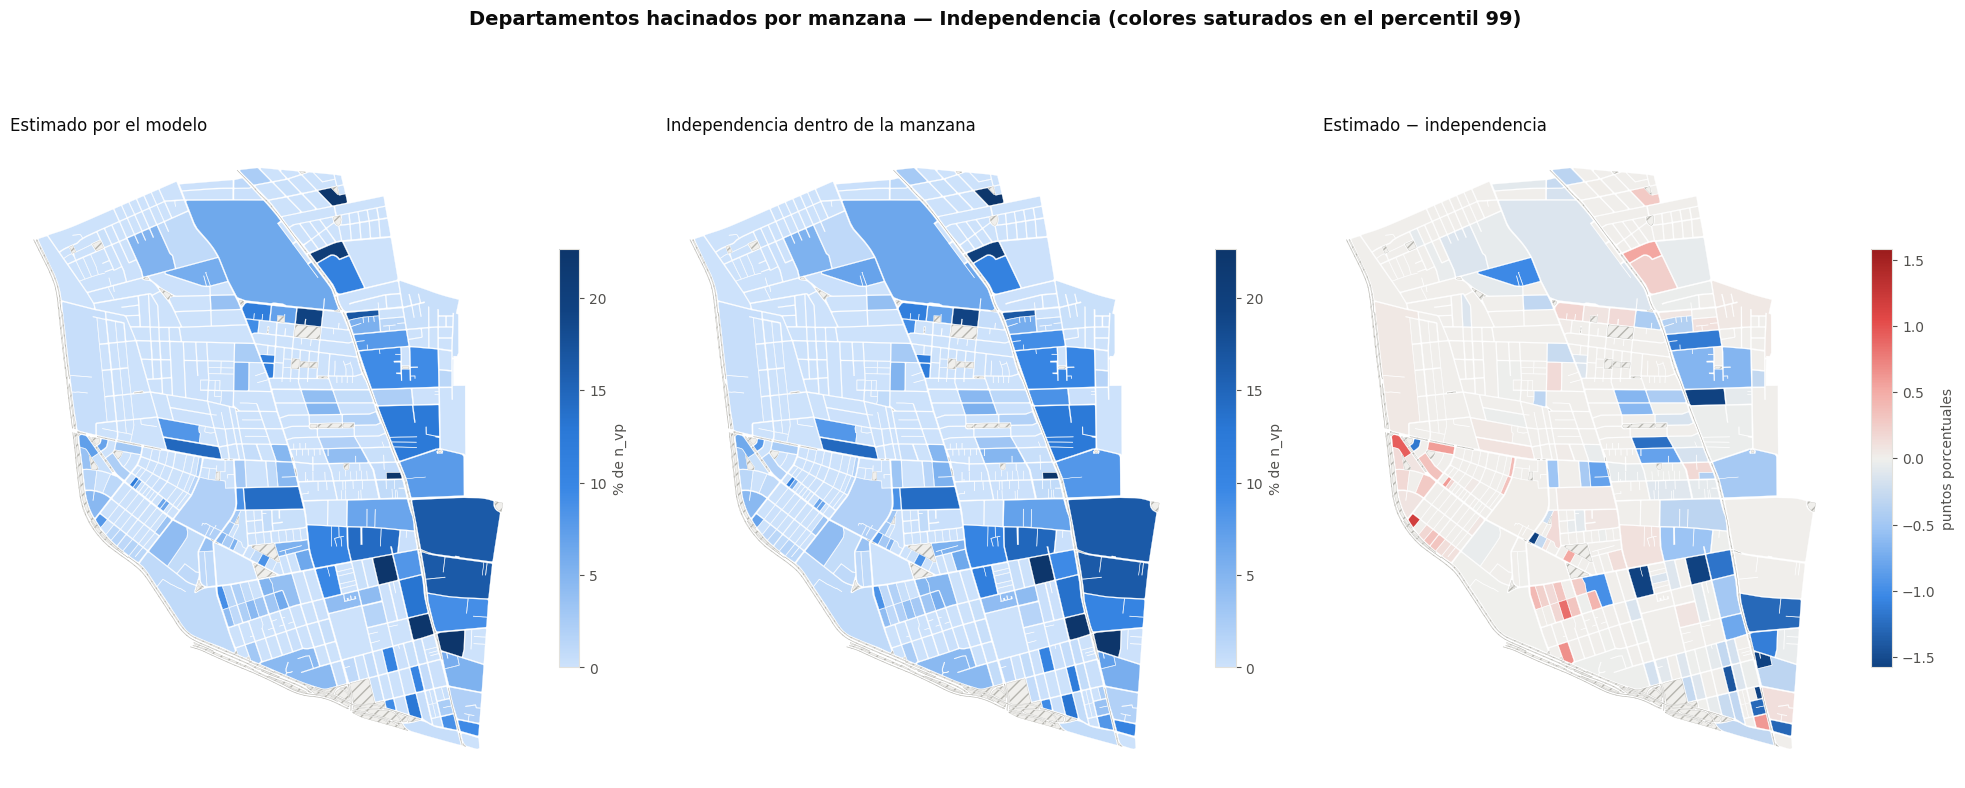

Hogares con jefatura femenina y menores de 15: estimado 7,630.0 | microdato 7,630 | independencia 7,031.0 | |diferencia| p95 = 2.33 pp


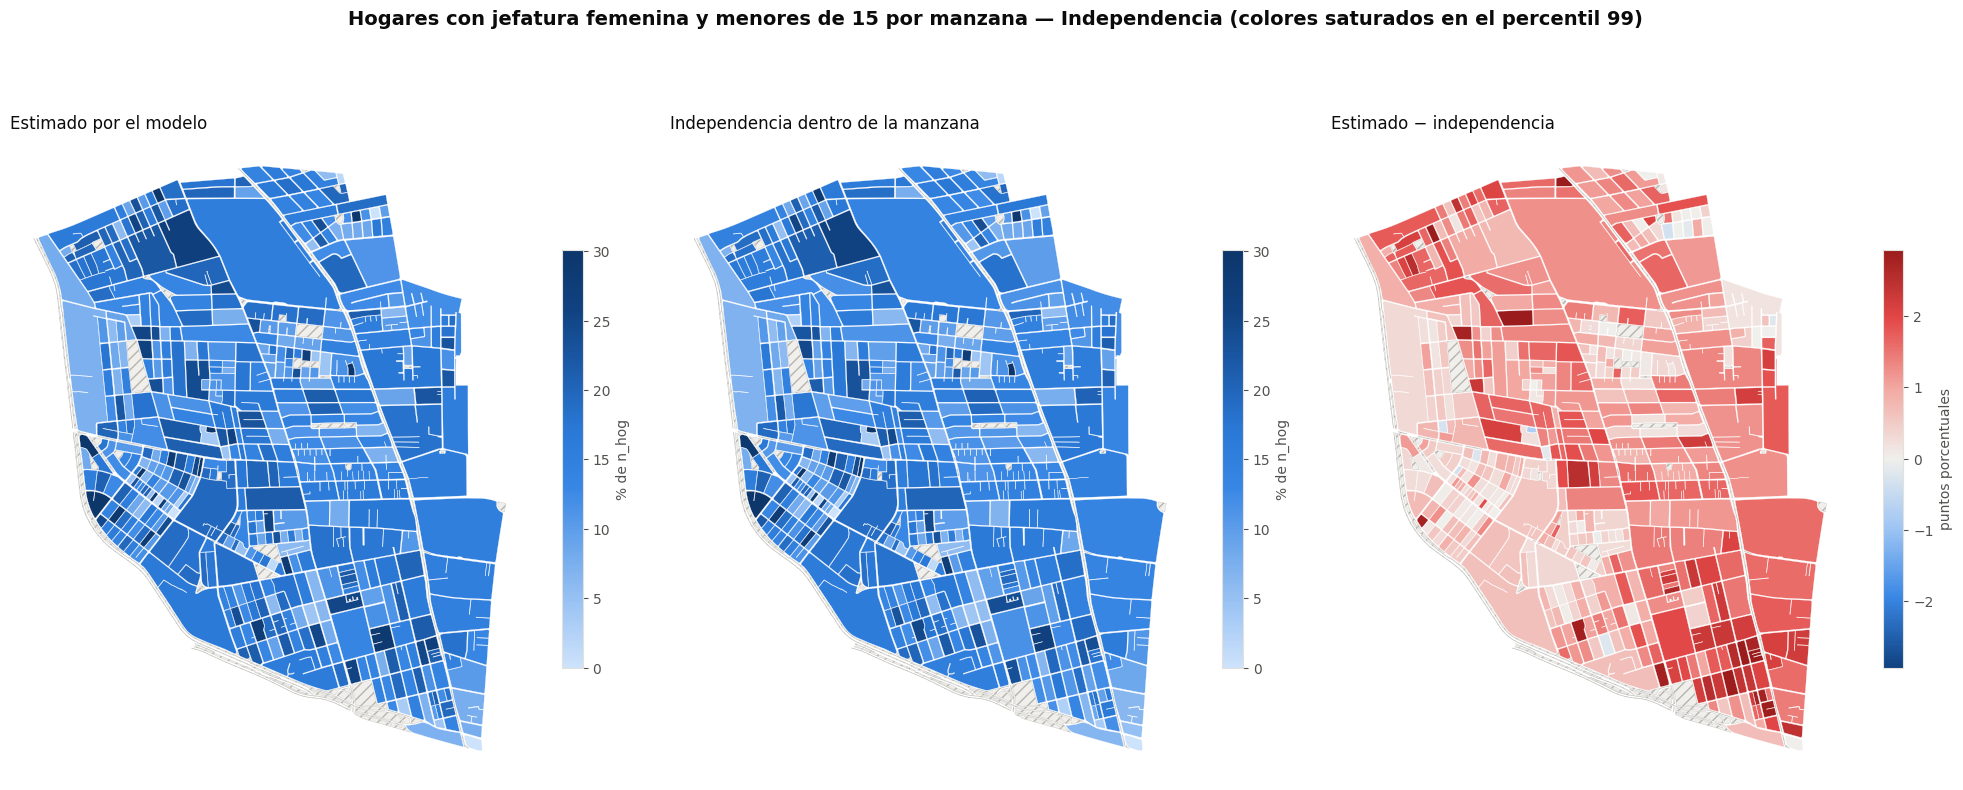

In [15]:
# H7b. Mapas de una celda de un cruce por manzana: estimado, independencia y diferencia
mapa_base = cargar_mapa(COMUNA_CUT)
sin_dato = {"color": "#f0efec", "edgecolor": "#b5b4ae", "hatch": "///", "label": "Sin unidades"}

def mapa_celda(unidad, var1, cat1, var2, cat2, titulo):
    datos, inv = inventarios[unidad]
    ids, n = datos.manzanas_ids, datos.nu.astype(float)
    cruces = pd.read_parquet(os.path.join(rutas_unidad(unidad)["cruces"], f"cruces_{COMUNA_CUT}.parquet"))
    par = cruces[(cruces["var1"] == var1) & (cruces["var2"] == var2)]
    assert len(par), f"no hay cruce {var1} × {var2}: {var1} debe ir antes que {var2} en el mapeo"
    por_manzana = lambda f: f.groupby("MANZENT")["conteo"].sum().reindex(ids, fill_value=0).to_numpy()
    celda = por_manzana(par[(par["cat1"] == cat1) & (par["cat2"] == cat2)])
    indep = por_manzana(par[par["cat1"] == cat1]) * por_manzana(par[par["cat2"] == cat2]) / n
    i1, i2 = etiquetas_bloque(inv, var1).index(cat1), etiquetas_bloque(inv, var2).index(cat2)
    micro = int(((codigos_bloque(inv, var1)[0] == i1) & (codigos_bloque(inv, var2)[0] == i2)).sum())
    df = pd.DataFrame({"MANZENT": ids, "estimado": 100 * celda / n, "independencia": 100 * indep / n})
    df["diferencia"] = df["estimado"] - df["independencia"]
    print(f"{titulo}: estimado {celda.sum():,.1f} | microdato {micro:,} | independencia {indep.sum():,.1f} "
          f"| |diferencia| p95 = {np.percentile(np.abs(df['diferencia']), 95):.2f} pp")
    mapa = mapa_base.merge(df, on="MANZENT", how="left")
    vmax = np.nanpercentile(df[["estimado", "independencia"]].to_numpy(), 99)
    vdif = np.nanpercentile(np.abs(df["diferencia"]), 99)
    fig, axes = plt.subplots(1, 3, figsize=(20, 9))
    for ax, col, sub, kw in [(axes[0], "estimado", "Estimado por el modelo", dict(cmap=SECUENCIAL, vmin=0, vmax=vmax)),
                             (axes[1], "independencia", "Independencia dentro de la manzana", dict(cmap=SECUENCIAL, vmin=0, vmax=vmax)),
                             (axes[2], "diferencia", "Estimado − independencia", dict(cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -vdif, vdif)))]:
        mapa.plot(column=col, linewidth=0.2, edgecolor="white", ax=ax, legend=True, missing_kwds=sin_dato,
                  legend_kwds={"label": "puntos porcentuales" if col == "diferencia" else f"% de {TOTAL[unidad]}", "shrink": 0.5}, **kw)
        ax.set_title(sub, loc="left")
        ax.axis("off")
    plt.suptitle(f"{titulo} por manzana — Independencia (colores saturados en el percentil 99)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

mapa_celda("viviendas", "tipo_viv", "tipo_viv_depto", "hacinamiento", "viv_hacinadas", "Departamentos hacinados")
mapa_celda("hogares", "con_menores", "hog_menores", "jefatura", "jefatura_mujer", "Hogares con jefatura femenina y menores de 15")

en venta o arriendo: estimado 3,119.0 | microdato 3,119 | desocupadas publicadas 4,426
manzanas con más viviendas en venta o arriendo (estimado):
       MANZENT  n_vp  desocupadas  venta_arriendo_est  depto
13108061002004  2576        878.0               641.4   2392
13108031003014   681        517.0               380.1    664
13108031005018  1024        403.0               293.7    960
13108071001001  1665        309.0               223.1   1564
13108051001002   250        191.0               140.3    241
13108041001005   994        169.0               120.9    865


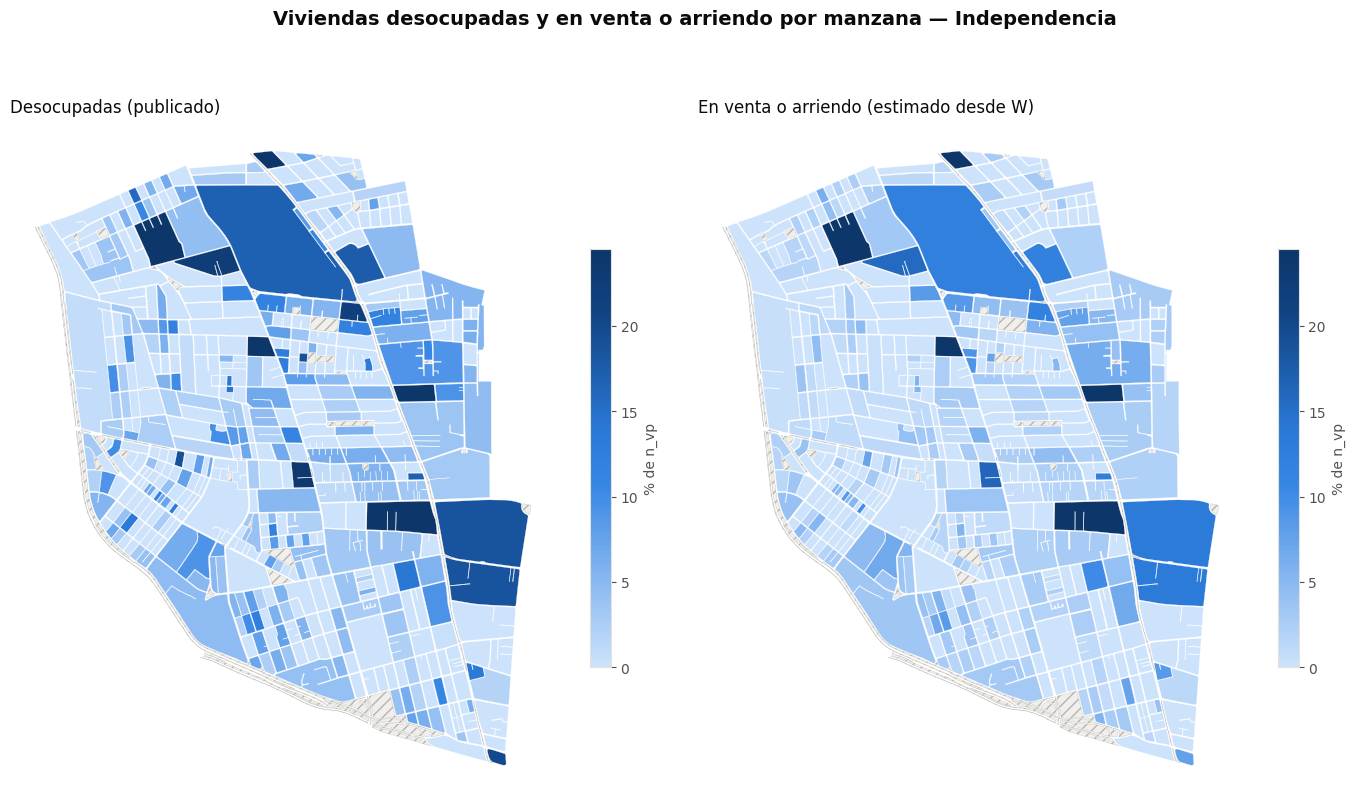

In [16]:
# H7c. Variable sin marginal por manzana: viviendas en venta o arriendo (p3b_estado_ocupacion = 7), desde W
datos, inv = inventarios["viviendas"]
modelo = modelos_13108["viviendas"]
n = datos.nu.astype(float)
venta = predecir_total(modelo, (datos.tabla["p3b_estado_ocupacion"] == 7).to_numpy())
desocupadas = pd.to_numeric(datos.manzanas["n_vp_desocupada"]).to_numpy(dtype=float)
print(f"en venta o arriendo: estimado {venta.sum():,.1f} | microdato {(datos.tabla['p3b_estado_ocupacion'] == 7).sum():,} "
      f"| desocupadas publicadas {desocupadas.sum():,.0f}")
print(f"manzanas con más viviendas en venta o arriendo (estimado):")
top = pd.DataFrame({"MANZENT": datos.manzanas_ids, "n_vp": datos.nu, "desocupadas": desocupadas, "venta_arriendo_est": venta.round(1),
                    "depto": pd.to_numeric(datos.manzanas["n_tipo_viv_depto"]).to_numpy()}).sort_values("venta_arriendo_est", ascending=False)
print(top.head(6).to_string(index=False))
df = pd.DataFrame({"MANZENT": datos.manzanas_ids, "desocupadas": 100 * desocupadas / n, "venta": 100 * venta / n})
mapa = mapa_base.merge(df, on="MANZENT", how="left")
vmax = np.nanpercentile(df[["desocupadas", "venta"]].to_numpy(), 99)
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, col, sub in [(axes[0], "desocupadas", "Desocupadas (publicado)"), (axes[1], "venta", "En venta o arriendo (estimado desde W)")]:
    mapa.plot(column=col, cmap=SECUENCIAL, vmin=0, vmax=vmax, linewidth=0.2, edgecolor="white", ax=ax, legend=True,
              missing_kwds=sin_dato, legend_kwds={"label": "% de n_vp", "shrink": 0.5})
    ax.set_title(sub, loc="left")
    ax.axis("off")
plt.suptitle("Viviendas desocupadas y en venta o arriendo por manzana — Independencia", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Conclusiones

1. **Hay dos modelos nuevos para todo el país, cada uno con su $W$ por comuna y su base de cruces.** Todas las comunas convergieron con el mismo criterio de personas.

   | | Viviendas | Hogares |
   |---|---|---|
   | Comunas | 345 (incluye 50 bajo umbral) | 345 (incluye 50 bajo umbral) |
   | Bloques y columnas | 13 bloques, 63 columnas | 15 bloques, 35 columnas |
   | GPU | 12 min (mediana 900 iteraciones) | 4 min (mediana 100 iteraciones) |
   | Cruces | 64 M filas, 308 MB | 85 M filas, 507 MB |
   | Modelos | 1,8 GB | 3,9 GB |

2. **El mapeo es exacto.** Las 98 columnas usadas cuadran con el microdato en las 345 comunas, sin celdas enmascaradas. *Viviendas irrecuperables* se reconstruyó como regla sobre tipo y materialidad y entra como bloque. Quedan fuera tres columnas del déficit habitacional que no se pueden reproducir: núcleos hacinados allegados, no ampliables y el déficit cuantitativo.

3. **Con verdad conocida (provincias → comunas), el modelo deja 0,37% de unidades mal ubicadas en las dos unidades.**
   - Viviendas: 0,37% contra 0,49% del raking de 2 bloques (24% menos) y 14,8% de la independencia. El modelo mejora al raking en los 67 pares no determinados por sus marginales. La independencia falla tanto porque las desocupadas caen en el resto de casi todos los bloques.
   - Hogares: 0,37% contra 0,58% (36% menos) y 3,4% de la independencia. Mejora 99 de 100 pares. La excepción, solo 60+ × teléfono móvil, empeora 3% sobre un error de 0,12%.
   - Los cruces más difíciles son paredes × techo (1,8%) en viviendas y tenencia × calefacción (2,3%) en hogares.

4. **Las variables sin marginal se estiman mejor con el modelo que con las alternativas.** Hogares por vivienda queda en 0,33% (1,4% condicionando en ocupación). El estado de ocupación detallado queda en 1,9% (3,0% y 5,7%), y la tipología del hogar en 2,0% (3,5% y 5,5%).

5. **En manzanas reales, el modelo predice bien totales que no usa.** Desde el modelo de viviendas, los hogares por manzana quedan con 2,3% de error relativo (0,8 hogares por manzana en promedio), contra 5,2% de repartir en proporción a las viviendas ocupadas. Las personas por manzana quedan con 6,5% contra 12,8% desde viviendas, y con 5,9% contra 11,2% desde hogares. Parte de ese error son personas en viviendas colectivas y en situación de calle, que ningún modelo ve.

6. **Privacidad: los cruces de viviendas son mucho más reveladores que los de personas.** El 29% de los perfiles de una sola vivienda concentra más de la mitad de su masa en una manzana, y todas las comunas superan el 5%. En hogares la cifra es 2,7% y en personas 0,71%. Los marginales de vivienda tienen categorías raras (pozo, sin electricidad, piso de tierra, mediagua) que ya ubican a esas viviendas, y el cruce agrega sus otros atributos. La base de viviendas no debería publicarse sin la Fase 2 o sin suprimir las celdas chicas.

7. **Mapas.** En hogares con jefatura femenina y menores de 15, la independencia dentro de la manzana da 7.031 en la comuna, y el modelo recupera el total del microdato (7.630). Por manzana corrige hasta 2,3 puntos porcentuales (percentil 95). Las viviendas en venta o arriendo, que no tienen marginal, se concentran según el modelo en las manzanas de edificios de departamentos con muchas desocupadas. Es inferencia, no dato.